# Figure 1

Scene-location learning (session 1 behavior).

In [1]:
import os.path as op
import os
os.environ.setdefault("OUTDATED_IGNORE", "1")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

from mgvs_release import config
from mgvs_release.bids import load_events
from mgvs_release.plotting import setup_style, push_to_back, save_fig
from mgvs_release.eyetracking import (
    ang_to_xy, ang_dist, parse_response_saccades,
)
from mgvs_release.stats import paired_ttest

In [2]:
setup_style()

In [3]:
bids_dir = config.BIDS_DIR
deriv_dir = config.DERIV_DIR
subjects = config.SUBJECTS

save_dir = '../plots/'
dataframes_dir = '../dataframes/'

## Load behavioral data

In [4]:
data = []

for s in subjects:
    df = load_events(bids_dir, s, task="learn")
    df['subject'] = s
    data.append(df)

data = pd.concat(data).reset_index(drop=True)

In [5]:
# Define control location
data['next_cont_ang'] = data['next_target_ang'] + -1 * (data['next_comp_ang'] - data['next_target_ang'])
data['next_cont_ang'] %= 360
cont_x, cont_y = zip(*data.apply(lambda x: ang_to_xy(x['next_cont_ang'], x['target_eccen']), axis=1).values)
data['next_cont_x'] = cont_x
data['next_cont_y'] = cont_y

## Load saccade data

In [6]:
sacc = parse_response_saccades(deriv_dir, subjects, task="learn", epoch=5) # Response period epoch

In [7]:
sacc_data = data.merge(sacc, on=['subject', 'run', 'trial'], how='outer')

In [8]:
sacc_data['sacc_targ_err'] = sacc_data.apply(
    lambda x: ang_dist(x['next_target_x'], x['next_target_y'], x['x_end'], x['y_end']), axis=1)
sacc_data['sacc_comp_err'] = sacc_data.apply(
    lambda x: ang_dist(x['next_comp_x'], x['next_comp_y'], x['x_end'], x['y_end']), axis=1)
sacc_data['sacc_cont_err'] = sacc_data.apply(
    lambda x: ang_dist(x['next_cont_x'], x['next_cont_y'], x['x_end'], x['y_end']), axis=1)

In [9]:
err_thresh = 22.5
sacc_data['comp_resp'] = sacc_data['sacc_comp_err'] < err_thresh
sacc_data['targ_resp'] = sacc_data['sacc_targ_err'] < err_thresh
sacc_data['cont_resp'] = sacc_data['sacc_cont_err'] < err_thresh

In [10]:
sacc_data_first = sacc_data.query("run_type=='test' & sacc_first==True")
sacc_data_last = sacc_data.query("run_type=='test' & sacc_last==True")

## Fig 1D: Competitor vs control saccades

In [11]:
subj_mean_no180 = sacc_data_last.query(
    "run_type=='test' & next_targ_comp_dist!=180"
).groupby(['subject']).mean(numeric_only=True).reset_index()

In [12]:
# More competitor than control saccades
paired_ttest(subj_mean_no180['comp_resp'], subj_mean_no180['cont_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,4.740806,31,two-sided,0.000045,"[0.03, 0.07]",1.245501,527.559,1.0


In [13]:
comp_cont_df = subj_mean_no180.melt(id_vars=['subject',],
                                       value_vars=['comp_resp', 'cont_resp'],
                                       var_name='resp_cat', value_name='prob')

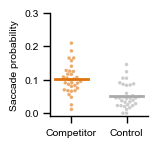

In [14]:
pal = ['#de730e', '#aaaaaa']
f, ax = plt.subplots(1, 1, figsize=(1.6, 1.5))

sns.swarmplot(x='resp_cat', y='prob', hue='resp_cat', palette=pal,
              size=2.5, alpha=.6, legend=False,
              data=comp_cont_df, ax=ax)

comp_mean = subj_mean_no180['comp_resp'].mean()
control_mean = subj_mean_no180['cont_resp'].mean()
ax.plot([-.3, .3], [comp_mean, comp_mean], c=pal[0], lw=2)
ax.plot([1-.3, 1+.3], [control_mean, control_mean], c=pal[1], lw=2)

ax.legend_ = None
ax.set(ylim=[-.01,.3], xlabel='', ylabel='Saccade probability',
       xticks=range(2), xticklabels=['Competitor', 'Control'])
plt.gcf().tight_layout()
sns.despine()

save_fig(plt.gcf(), op.join(save_dir, 'fig1d'))

## Fig 1E: Target vs competitor saccades over learning

In [15]:
first_ = sacc_data_last.query("run==2 or run==8").copy()
first_['run_cat'] = 'first'

last_=[]
for (subj, stim), g in sacc_data_last.query("run_type=='test'").groupby(['subject', 'stim_name']):
    max_r = g['run'].max()
    last_.append(g.query("run==@max_r"))
last_ = pd.concat(last_).reset_index(drop=True)
last_['run_cat'] = 'last'

first_last = pd.concat([first_, last_]).reset_index(drop=True)

In [16]:
first_last_mean = first_last.groupby(['subject', 'run_cat']).mean(numeric_only=True).reset_index()

In [17]:
# Target saccades increase from first to last test
paired_ttest(first_last_mean.query("run_cat=='last'")['targ_resp'],
             first_last_mean.query("run_cat=='first'")['targ_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,9.822864,31,two-sided,4.902486e-11,"[0.24, 0.36]",1.737488,1.981e+08,1.0


In [18]:
# Competitor saccades decrease from first to last test
paired_ttest(first_last_mean.query("run_cat=='last'")['comp_resp'],
             first_last_mean.query("run_cat=='first'")['comp_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-5.597255,31,two-sided,0.000004,"[-0.1, -0.05]",1.486277,5004.063,1.0


In [19]:
first_last_df = first_last_mean.melt(id_vars=['subject', 'run_cat'],
                                     value_vars=['targ_resp', 'comp_resp'],
                                     var_name='resp_cat', value_name='prob')

In [20]:
# There is an interaction between response type (target, competitor) and test run (first, last)
pg.rm_anova(data=first_last_df, dv='prob', within=['resp_cat', 'run_cat'], subject='subject', effsize='np2')

,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,np2,eps
0,resp_cat,6.246386,1,31,6.246386,266.989527,8.731440e-17,8.731440e-17,0.895969,1.0
1,run_cat,0.402314,1,31,0.402314,66.819659,3.119625e-09,3.119625e-09,0.683090,1.0
2,resp_cat * run_cat,1.120113,1,31,1.120113,95.772135,5.354520e-11,5.354520e-11,0.755467,1.0


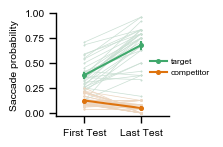

In [21]:
pal = ['#40a86c', '#de730e']

f, ax = plt.subplots(1, 1, figsize=(2.15, 1.5))


sns.pointplot(hue='subject', y='prob', x='run_cat', errorbar='se', ax=ax,
              linewidth=.5, ms=1, palette=[sns.desaturate('#c5e4d2', .7)] * len(config.SUBJECTS),
              data=first_last_df.query("resp_cat=='targ_resp'"))

sns.pointplot(hue='subject', y='prob', x='run_cat', errorbar='se', ax=ax,
              linewidth=.5, palette=[sns.desaturate('#f5d5b6', .7)] * len(config.SUBJECTS),
              data=first_last_df.query("resp_cat=='comp_resp'"))
push_to_back(ax)

sns.pointplot(hue='resp_cat', y='prob', x='run_cat', errorbar='se', ax=ax,
              linewidth=1.5, ms=2.5,
              hue_order=['targ_resp', 'comp_resp'],
             palette=pal, data=first_last_df)

ax.set(xlabel='', xticks=range(2), xticklabels=['First Test', 'Last Test'],
       ylim=[-.035, 1], yticks=[0, .25, .5, .75, 1], ylabel='Saccade probability')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[-2:], ['target',  'competitor'], frameon=False, fontsize=6, handletextpad=.5,
         bbox_to_anchor=(.8, .6),
         loc='upper left', borderaxespad=0.,)
sns.despine()
f.tight_layout()
save_fig(f, op.join(save_dir, 'fig1e'))

In [22]:
first_last_mean.to_csv(op.join(dataframes_dir, 'learn_subj_firstlast.csv'), index=False)